## SST

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

import sys
from pathlib import Path
import os

from scipy.io import loadmat
from helper import plot_training_curves, evaluate_model, plot_reconstruction, plot_sst_with_buoys, plot_sst_overview_and_availability

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))
DATA_DIR = Path.cwd() / "datasets"  

from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Exploration

In [4]:
# Load SST data -> X RAW
X_raw = np.load(DATA_DIR / "sst_all_ROM.npy")
print(f"Loaded SST data with shape: {X_raw.shape}")
S_raw = np.load(DATA_DIR / "buoy_all_ROM.npy")
print(f"Loaded Buoy data with shape: {S_raw.shape}\n")

loc = pd.read_csv(DATA_DIR / "stations_location.csv", dtype={"station": str})
S_names = loc["station"].to_numpy()
S_lat = loc["lat"].to_numpy()
S_lon = loc["lon"].to_numpy()

for i, name in enumerate(S_names):
    print(f"Buoy {name} at lat: {S_lat[i]}, lon: {S_lon[i]}")

X_raw = X_raw.reshape(-1, 180 * 360)
S_raw = S_raw.reshape(-1, 20)

print(f"\nReshaped X_raw to: {X_raw.shape}")
print(f"Reshaped S_raw to: {S_raw.shape}")

Loaded SST data with shape: (26, 365, 64800)
Loaded Buoy data with shape: (26, 365, 20)

Buoy 46035 at lat: 57.034, lon: -177.468
Buoy 46001 at lat: 56.296, lon: -148.027
Buoy 46066 at lat: 52.776, lon: -154.992
Buoy 46006 at lat: 40.73, lon: -137.42
Buoy 46059 at lat: 38.067, lon: -129.895
Buoy 46025 at lat: 33.765, lon: -119.077
Buoy 51001 at lat: 24.475, lon: -162.03
Buoy 51004 at lat: 17.504, lon: -152.197
Buoy 52200 at lat: 13.354, lon: 144.788
Buoy 44013 at lat: 42.346, lon: -70.651
Buoy 41001 at lat: 34.738, lon: -72.503
Buoy 41010 at lat: 28.86, lon: -78.478
Buoy 41046 at lat: 23.84, lon: -68.34
Buoy 41043 at lat: 21.09, lon: -64.864
Buoy 41044 at lat: 21.582, lon: -58.63
Buoy 42057 at lat: 16.975, lon: -81.578
Buoy 42058 at lat: 14.114, lon: -75.949
Buoy 42040 at lat: 29.207, lon: -88.237
Buoy 42001 at lat: 25.922, lon: -89.638
Buoy 42002 at lat: 25.95, lon: -93.78

Reshaped X_raw to: (9490, 64800)
Reshaped S_raw to: (9490, 20)


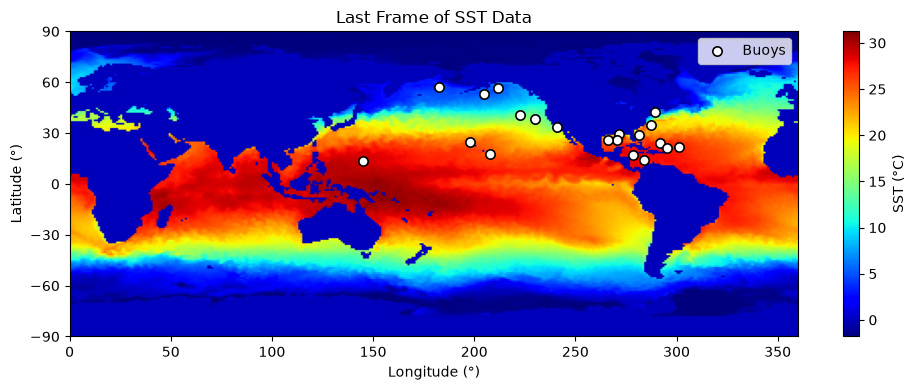

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Load SST data -> X CLEAN
mean_X = np.mean(X_raw, axis=0)
sst_locs = np.where(mean_X != 0)[0]

X_clean = X_raw[:, sst_locs]
S_clean = S_raw

# Plot dell'ultimo frame
fig, ax = plot_sst_with_buoys(X_raw, S_lon, S_lat)

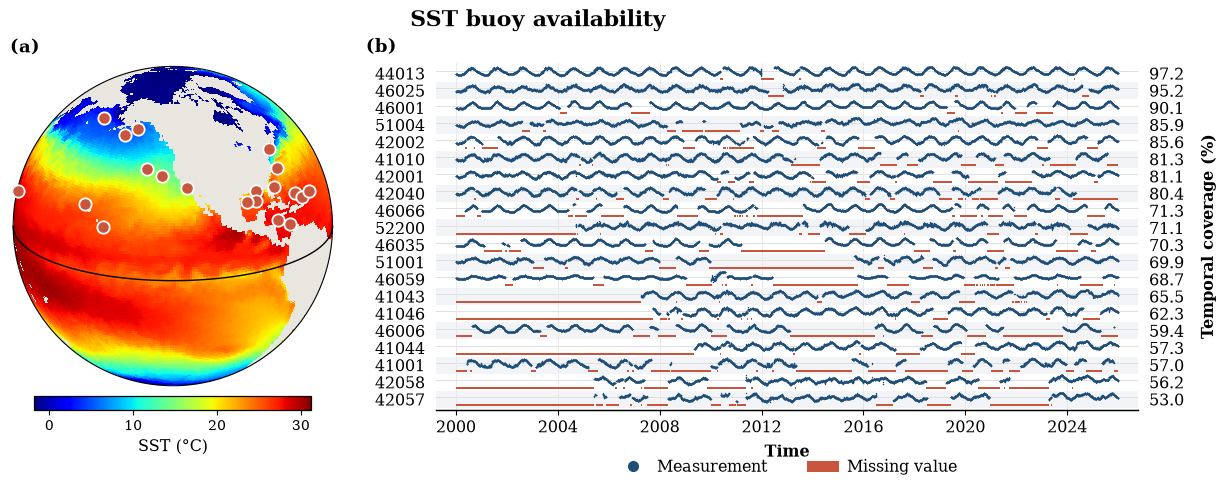

In [6]:
years = range(2000, 2026)
time = np.concatenate(
    [pd.date_range(f"{y}-01-01", periods=365, freq="D") for y in years]
)
assert len(time) == X_raw.shape[0] == S_raw.shape[0]  # 9490

fig, axs, cov = plot_sst_overview_and_availability(
    X_raw, S_lon, S_lat, S_names,
    time=time,
    X_buoys=S_raw,   # dati reali delle boe, con i NaN
    savepath="SST_1_availability.png",
    rotate_deg=-30.0
)